# Titanic · исследование данных

Одна строка — один пассажир. Цель `Survived`: **0 — не выжил, 1 — выжил**.
Здесь собраны текущие исследования обучающего файла `train.csv`.

**Содержание:** знакомство с данными → пропуски → возраст → пол и выживание →
класс билета → родственники → предварительные выводы и вопросы.

Доли всегда относятся к указанной группе. Найденные связи не доказывают причинность.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 16,
    "grid.alpha": 0.25,
})
pd.set_option("display.precision", 2)

main_color = "#287D8E"
sex_order = ["female", "male"]
sex_labels = ["Женщины", "Мужчины"]
sex_colors = ["#287D8E", "#E5AB50"]

## 1. Знакомство с данными

`Pclass` — порядковая категория (1-й, 2-й, 3-й класс), `Age` — возраст в годах.
`SibSp` и `Parch` отражают указанных в данных родственников на борту.
`Embarked` — порт посадки пассажира; `Fare` — стоимость билета.

In [2]:
df = pd.read_csv("data/train.csv")
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.05,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.46,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.86,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.07,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.13,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.07,NaN,C


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 2. Пропуски

**Вопрос:** какие сведения отсутствуют чаще всего?
Знаменатель для каждого процента — все строки исходной таблицы.

In [4]:
missing_summary = pd.DataFrame({
    "Пропусков": df.isna().sum(),
    "Доля пропусков, %": df.isna().mean() * 100,
})
missing_summary = missing_summary.loc[missing_summary["Пропусков"] > 0]
missing_summary = missing_summary.sort_values("Доля пропусков, %", ascending=False)
missing_summary

,Пропусков,"Доля пропусков, %"
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


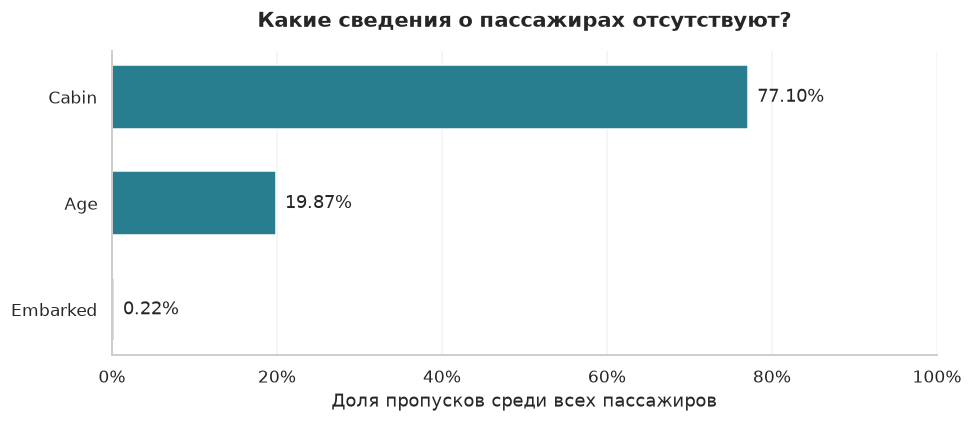

In [5]:
missing_pct = missing_summary["Доля пропусков, %"].sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(missing_pct.index, missing_pct.values, color=main_color, height=0.6)
ax.set_title("Какие сведения о пассажирах отсутствуют?")
ax.set_xlabel("Доля пропусков среди всех пассажиров")
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.bar_label(bars, fmt="%.2f%%", padding=6)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

**Наблюдение:** пропущено 77,10% значений `Cabin`, 19,87% — `Age`, 0,22% — `Embarked`.
Пропуск означает отсутствие сведений, а не отсутствие каюты или нулевой возраст.
Решение об обработке пока не принято.

## 3. Возраст пассажиров

**Вопрос:** как распределён известный возраст?
В следующих двух графиках участвуют 714 пассажиров. Ещё у 177 возраст неизвестен.

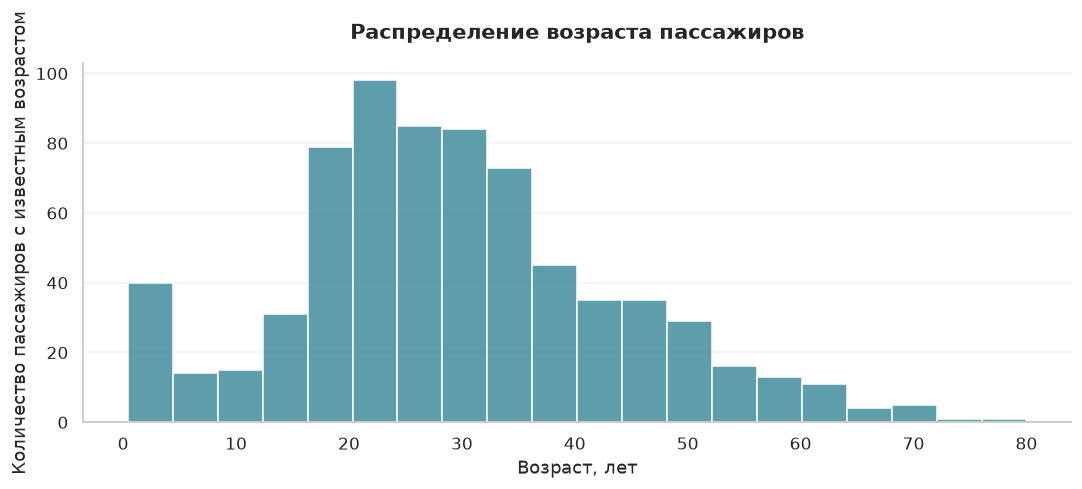

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(data=df, x="Age", bins=20, color=main_color, edgecolor="white", ax=ax)
ax.set_title("Распределение возраста пассажиров")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Количество пассажиров с известным возрастом")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

### Возрастные группы

Следующий график показывает долю каждой возрастной группы **среди пассажиров с известным возрастом**.
Это распределение возраста, а не доля выживших.
В интервале `(20, 30]` левая граница исключена, правая включена: старше 20 и не старше 30 лет.

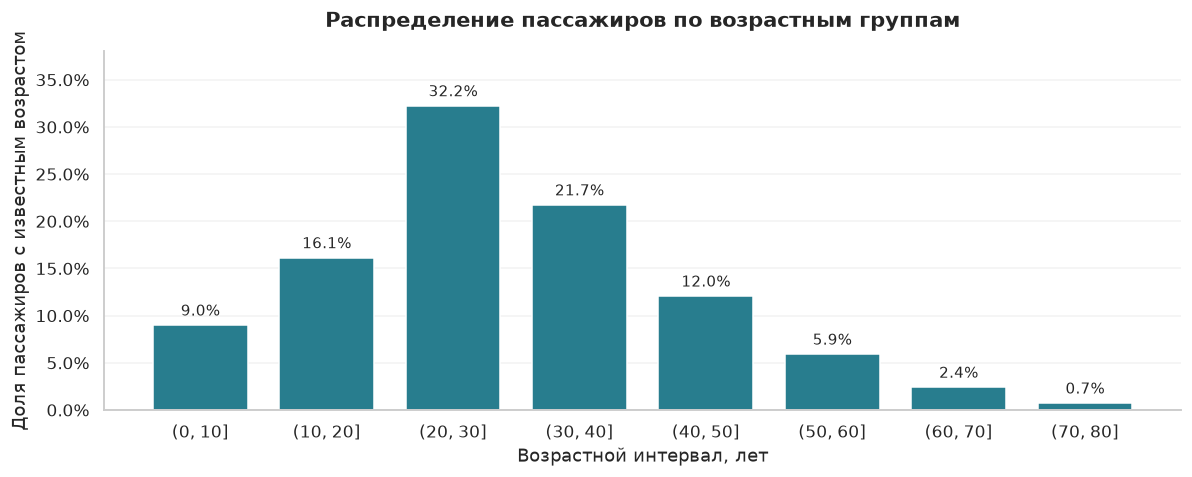

In [7]:
age_edges = [0, 10, 20, 30, 40, 50, 60, 70, 80]
age_groups = pd.cut(df["Age"], bins=age_edges, right=True)
age_group_pct = age_groups.value_counts(normalize=True).sort_index() * 100
age_labels = [f"({interval.left}, {interval.right}]" for interval in age_group_pct.index]

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(age_labels, age_group_pct.values, color=main_color, width=0.75)
ax.set_title("Распределение пассажиров по возрастным группам")
ax.set_xlabel("Возрастной интервал, лет")
ax.set_ylabel("Доля пассажиров с известным возрастом")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(0, age_group_pct.max() * 1.18)
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=10)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

**Наблюдение:** самая многочисленная из выбранных групп — старше 20 и до 30 лет включительно.
На гистограмме в старших возрастах наблюдений меньше. Вид гистограммы зависит от границ интервалов;
данные с неизвестным возрастом здесь не представлены.

## 4. Пол и выживание

**Вопросы:** какова доля выживших среди женщин и среди мужчин? Каков состав самих выживших?
Это разные вопросы с разными знаменателями.

In [8]:
survival_summary = pd.DataFrame({
    "Пассажиров": df["Survived"].value_counts().sort_index(),
    "Доля всех пассажиров, %": df["Survived"].value_counts(normalize=True).sort_index() * 100,
})
survival_summary.index = survival_summary.index.map({0: "Не выжили", 1: "Выжили"})
survival_summary

,Пассажиров,"Доля всех пассажиров, %"
Survived,,
Не выжили,549,61.62
Выжили,342,38.38


In [9]:
survival_by_sex = df.groupby("Sex")["Survived"].agg(
    passengers="size", survivors="sum", survival_rate="mean"
).reindex(sex_order)
survival_by_sex["survival_rate"] *= 100
survival_by_sex.rename(columns={
    "passengers": "Всего пассажиров",
    "survivors": "Выжили",
    "survival_rate": "Доля выживших внутри группы, %",
})

,Всего пассажиров,Выжили,"Доля выживших внутри группы, %"
Sex,,,
female,314,233,74.20
male,577,109,18.89


**Наблюдение:** среди всех женщин выжили 74,2%, среди всех мужчин — 18,9%.
Эти проценты не должны складываться в 100%: у каждого свой знаменатель.

В таблице ниже другой знаменатель — **все пассажиры**. Каждая внутренняя ячейка показывает
долю соответствующего сочетания пола и исхода во всей выборке.

In [10]:
sex_outcome_pct = pd.crosstab(
    df["Sex"], df["Survived"], normalize=True, margins=True
) * 100
sex_outcome_pct.rename(
    index={"female": "Женщины", "male": "Мужчины", "All": "Всего"},
    columns={0: "Не выжили", 1: "Выжили", "All": "Всего"},
)

Survived,Не выжили,Выжили,Всего
Sex,,,
Женщины,9.09,26.15,35.24
Мужчины,52.53,12.23,64.76
Всего,61.62,38.38,100.00


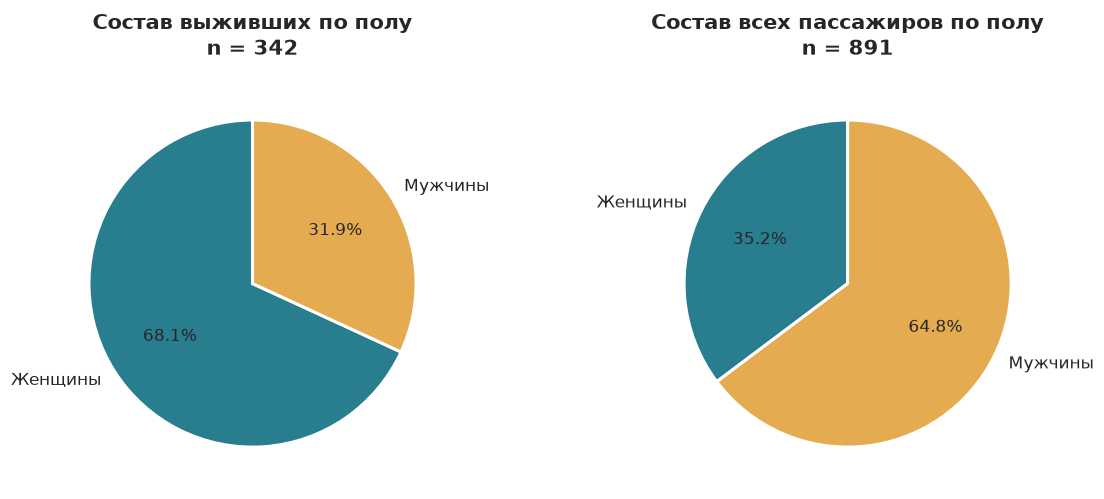

In [11]:
survivor_sex_counts = df.loc[df["Survived"] == 1, "Sex"].value_counts().reindex(sex_order)
all_sex_counts = df["Sex"].value_counts().reindex(sex_order)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.7))
for ax, counts, title in zip(
    axes,
    [survivor_sex_counts, all_sex_counts],
    ["Состав выживших по полу", "Состав всех пассажиров по полу"],
):
    ax.pie(
        counts,
        labels=sex_labels,
        colors=sex_colors,
        autopct="%1.1f%%",
        startangle=90,
        wedgeprops={"edgecolor": "white", "linewidth": 2},
        textprops={"fontsize": 11},
    )
    ax.set_title(f"{title}\nn = {counts.sum()}")
    ax.set_aspect("equal")

fig.tight_layout()
plt.show()

Среди **выживших** женщины составляют 68,1%, мужчины — 31,9%.
Эти две доли складываются в 100%. Во всех диаграммах женщины обозначены бирюзовым,
мужчины — золотистым.

## 5. Класс билета и выживание

**Вопрос:** различается ли доля выживших между классами?
В основной таблице знаменатель — все пассажиры соответствующего класса.

In [12]:
survival_by_class = df.groupby("Pclass")["Survived"].agg(
    passengers="size", survivors="sum", survival_rate="mean"
)
survival_by_class["survival_rate"] *= 100
survival_by_class.rename(columns={
    "passengers": "Всего пассажиров",
    "survivors": "Выжили",
    "survival_rate": "Доля выживших внутри класса, %",
})

,Всего пассажиров,Выжили,"Доля выживших внутри класса, %"
Pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


In [13]:
class_outcome_pct = df.value_counts(["Pclass", "Survived"], normalize=True).sort_index() * 100
class_outcome_pct.rename("Доля всех пассажиров, %").to_frame()

Доля всех пассажиров, %
Pclass Survived                         
1      0                            8.98
       1                           15.26
2      0                           10.89
       1                            9.76
3      0                           41.75
       1                           13.36

**Наблюдение:** доли выживших в 1-м, 2-м и 3-м классах составляют 63,0%, 47,3% и 24,2%.
В этой выборке более высокому классу обслуживания соответствует большая доля выживших.
Это наблюдаемая связь, а не доказанный причинный эффект класса билета.

Следующие расчёты рассматривают состав классов по полу и исходы внутри сочетаний класса и пола.

In [14]:
sex_pct_by_class = df.groupby("Pclass")["Sex"].value_counts(normalize=True) * 100
sex_pct_by_class.rename("Доля внутри класса, %").to_frame()

Доля внутри класса, %
Pclass Sex                          
1      male                    56.48
       female                  43.52
2      male                    58.70
       female                  41.30
3      male                    70.67
       female                  29.33

In [15]:
outcome_pct_by_class_sex = (
    df.groupby(["Pclass", "Sex"])["Survived"].value_counts(normalize=True) * 100
)
outcome_pct_by_class_sex.rename("Доля внутри группы класса и пола, %").to_frame()

Доля внутри группы класса и пола, %
Pclass Sex    Survived                                     
1      female 1                                       96.81
              0                                        3.19
       male   0                                       63.11
              1                                       36.89
2      female 1                                       92.11
              0                                        7.89
       male   0                                       84.26
              1                                       15.74
3      female 1                                       50.00
              0                                       50.00
       male   0                                       86.46
              1                                       13.54

## 6. Родственники на борту

**Гипотеза:** число указанных родственников может быть связано с выживанием.
`Parch_and_SibSp` — сумма двух исходных счётчиков; сам пассажир в неё не включён.
Нулевое значение не доказывает, что человек путешествовал без любых сопровождающих.

In [16]:
df["Parch_and_SibSp"] = df["Parch"] + df["SibSp"]
relative_count_pct = df["Parch_and_SibSp"].value_counts(normalize=True).sort_index() * 100
relative_count_pct.rename("Доля всех пассажиров, %").to_frame()

,"Доля всех пассажиров, %"
Parch_and_SibSp,
0,60.27
1,18.07
2,11.45
3,3.25
4,1.68
5,2.47
6,1.35
7,0.67
10,0.79


In [17]:
family_survival = df.groupby(["Parch_and_SibSp", "Sex"])["Survived"].agg(
    passengers="size", survival_rate="mean"
)
family_survival["survival_rate"] *= 100
family_survival.rename(columns={
    "passengers": "Пассажиров в группе",
    "survival_rate": "Доля выживших внутри группы, %",
})

Пассажиров в группе  Доля выживших внутри группы, %
Parch_and_SibSp Sex                                                        
0               female                  126                           78.57
                male                    411                           15.57
1               female                   87                           81.61
                male                     74                           24.32
2               female                   49                           77.55
                male                     53                           39.62
3               female                   19                           84.21
                male                     10                           50.00
4               female                   12                           25.00
                male                      3                            0.00
5               female                    8                           37.50
                male                     14                            0.00
6               female                    8                           37.50
                male                      4                           25.00
7               female                    2                            0.00
                male                      4                            0.00
10              female                    3                            0.00
                male                      4                            0.00

**Наблюдение:** у 60,3% пассажиров сумма `SibSp` и `Parch` равна нулю.
Предположение «чем больше родственников, тем выше выживаемость» пока не подтверждено.
Это также не доказывает обратную монотонную связь: при сравнении нужно учитывать размеры групп.

### Отдельные расчёты для Parch и SibSp

Сохранены оба направления исследования. Для доли выживших знаменатель — соответствующая группа,
а для распределения числа родственников по классам — пассажиры данного класса.

In [18]:
parch_survival = df.groupby("Parch")["Survived"].mean() * 100
display(parch_survival.rename("Доля выживших внутри группы Parch, %").to_frame())

parch_group_survival = df.groupby(["Parch", "Pclass", "Sex"])["Survived"].mean() * 100
display(parch_group_survival.rename("Доля выживших внутри группы, %").to_frame())

parch_pct_by_class = df.groupby("Pclass")["Parch"].value_counts(normalize=True) * 100
display(parch_pct_by_class.rename("Доля внутри класса, %").to_frame())

,"Доля выживших внутри группы Parch, %"
Parch,
0,34.37
1,55.08
2,50.00
3,60.00
4,0.00
5,20.00
6,0.00


Доля выживших внутри группы, %
Parch Pclass Sex                                   
0     1      female                           98.44
             male                             36.36
      2      female                           88.89
             male                              8.99
      3      female                           58.82
             male                             12.16
1     1      female                          100.00
             male                             28.57
      2      female                           94.44
             male                             50.00
      3      female                           48.00
             male                             26.67
2     1      female                           84.62
             male                             62.50
      2      female                          100.00
             male                             40.00
      3      female                           32.00
             male                             16.67
3     2      female                          100.00
      3      female                           50.00
             male                              0.00
4     1      male                              0.00
      3      female                            0.00
             male                              0.00
5     3      female                           25.00
             male                              0.00
6     3      female                            0.00

Доля внутри класса, %
Pclass Parch                       
1      0                      75.46
       1                      14.35
       2                       9.72
       4                       0.46
2      0                      72.83
       1                      17.39
       2                       8.70
       3                       1.09
3      0                      77.60
       1                      11.20
       2                       8.76
       5                       1.02
       4                       0.61
       3                       0.61
       6                       0.20

In [19]:
sibsp_survival = df.groupby("SibSp")["Survived"].mean() * 100
display(sibsp_survival.rename("Доля выживших внутри группы SibSp, %").to_frame())

sibsp_group_survival = df.groupby(["SibSp", "Sex"])["Survived"].mean() * 100
display(sibsp_group_survival.rename("Доля выживших внутри группы, %").to_frame())

sibsp_pct_by_class = df.groupby("Pclass")["SibSp"].value_counts(normalize=True) * 100
display(sibsp_pct_by_class.rename("Доля внутри класса, %").to_frame())

,"Доля выживших внутри группы SibSp, %"
SibSp,
0,34.54
1,53.59
2,46.43
3,25.00
4,16.67
5,0.00
8,0.00


Доля выживших внутри группы, %
SibSp Sex                                   
0     female                           78.74
      male                             16.82
1     female                           75.47
      male                             31.07
2     female                           76.92
      male                             20.00
3     female                           36.36
      male                              0.00
4     female                           33.33
      male                              8.33
5     female                            0.00
      male                              0.00
8     female                            0.00
      male                              0.00

Доля внутри класса, %
Pclass SibSp                       
1      0                      63.43
       1                      32.87
       2                       2.31
       3                       1.39
2      0                      65.22
       1                      29.89
       2                       4.35
       3                       0.54
3      0                      71.49
       1                      16.90
       4                       3.67
       2                       3.05
       3                       2.44
       8                       1.43
       5                       1.02

## 7. Предварительные выводы и открытые вопросы

- В выборке есть связь выживания с полом и классом билета. Доли внутри групп нельзя путать с составом выживших.
- В более высоком классе обслуживания доля женщин выше; это повод рассматривать признаки совместно.
- Доля отсутствующих сведений особенно велика для кают. Решение об удалении или заполнении пока не принято.
- Известный возраст чаще попадает в интервал `(20, 30]`, чем в другие выбранные десятилетние интервалы.
- У 60,3% пассажиров не указаны родственники в `SibSp` и `Parch`. Вывод о связи их числа с выживанием остаётся предварительным.

**Вопросы для дальнейшего исследования:**

1. Как различается распределение возраста между полами?
2. Как связаны возраст и выживание?
3. Меняется ли связь числа родственников с выживанием при учёте пола и возраста?
4. Есть ли связь между сведениями о каюте и выживанием?


## Дополнение. Сохранённые расчёты по точному возрасту

Ранее выполненные пробы оставлены отдельно, чтобы не перегружать основной анализ.
Здесь нет группировки по возрастным интервалам. Пассажиры без возраста не участвуют;
маленькие группы требуют осторожной интерпретации.

In [20]:
display(df.groupby("Age")["Survived"].value_counts().rename("Пассажиров").to_frame())
display(df[["Age", "Survived"]].corr())
display(pd.crosstab(df["Age"], df["Survived"]))

,,Пассажиров
Age,Survived,
0.42,1,1
0.67,1,1
0.75,1,2
0.83,1,2
0.92,1,1
...,...,...
70.00,0,2
70.50,0,1
71.00,0,2


,Age,Survived
Age,1.00,-0.08
Survived,-0.08,1.00


Survived,0,1
Age,,
0.42,0,1
0.67,0,1
0.75,0,2
0.83,0,2
0.92,0,1
...,...,...
70.00,2,0
70.50,1,0
71.00,2,0
